# Art Medium Classification
## Team members
1) Rekha Dhorigol - PES1UG24CS370
2) CH Yashwitha - PES1UG24CS121
3) Salasha Vijay - PES1UG24CS689
4) Fathima Zahra - PES1UG24CS664



# Initial setup

In [1]:
!pip install -q --upgrade torch torchvision scikit-learn seaborn

In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Training may take longer.")

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import files
uploaded = files.upload()

Saving processed.zip to processed.zip


In [4]:
import zipfile
import os

zip_path = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/dataset")

DATASET_PATH = "/content/dataset/processed"

print(os.listdir(DATASET_PATH))

['ink', 'oil', 'graphite', 'pastel', 'watercolour']


In [5]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [6]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

In [7]:
base_dataset = datasets.ImageFolder(DATASET_PATH)

class_names = base_dataset.classes
labels = np.array(base_dataset.targets)
indices = np.arange(len(labels))

print("Classes:", class_names)
print("Total images:", len(base_dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

# Separate dataset objects allow different transformations
train_dataset_full = datasets.ImageFolder(
    DATASET_PATH,
    transform=train_transform
)

eval_dataset_full = datasets.ImageFolder(
    DATASET_PATH,
    transform=test_transform
)

train_dataset = Subset(train_dataset_full, train_idx)
val_dataset = Subset(eval_dataset_full, val_idx)
test_dataset = Subset(eval_dataset_full, test_idx)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['graphite', 'ink', 'oil', 'pastel', 'watercolour']
Total images: 125
Training images: 87
Validation images: 19
Testing images: 19


In [8]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


# ResNet & MViT

In [10]:
import torch
import torch.nn as nn
from torchvision import models

def create_resnet(num_classes):

    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Freeze pretrained backbone
    for param in model.parameters():
        param.requires_grad = False

    # Replace final classification layer
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    # Allow the new classification layer to learn
    for param in model.fc.parameters():
        param.requires_grad = True

    return model


resnet_model = create_resnet(len(class_names))

print("ResNet-18 created successfully!")

ResNet-18 created successfully!


In [11]:
import torch
import torch.nn as nn

from torchvision.models.video import (
    mvit_v2_s,
    MViT_V2_S_Weights
)


class ImageMViT(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # Load pretrained MViT V2-S
        self.model = mvit_v2_s(
            weights=MViT_V2_S_Weights.DEFAULT
        )

        # Freeze pretrained backbone
        for param in self.model.parameters():
            param.requires_grad = False

        # Find final linear layer
        linear_layers = [
            (name, layer)
            for name, layer in self.model.head.named_modules()
            if isinstance(layer, nn.Linear)
        ]

        final_name, final_layer = linear_layers[-1]

        # Replace final classification layer
        new_layer = nn.Linear(
            final_layer.in_features,
            num_classes
        )

        if "." in final_name:
            parent_name, child_name = final_name.rsplit(".", 1)
            parent = self.model.head.get_submodule(parent_name)
            setattr(parent, child_name, new_layer)
        else:
            self.model.head[int(final_name)] = new_layer

        # Train only the new classification layer
        for param in new_layer.parameters():
            param.requires_grad = True

    def forward(self, images):

        # Convert image batch into 16-frame video clips
        video = images.unsqueeze(2).repeat(1, 1, 16, 1, 1)

        return self.model(video)


def create_mvit(num_classes):
    return ImageMViT(num_classes)


mvit_model = create_mvit(len(class_names))

print("MViT V2-S created successfully!")

Downloading: "https://download.pytorch.org/models/mvit_v2_s-ae3be167.pth" to /root/.cache/torch/hub/checkpoints/mvit_v2_s-ae3be167.pth


100%|██████████| 132M/132M [00:01<00:00, 126MB/s]


MViT V2-S created successfully!


# Train-eval functions

In [12]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


def evaluate(model, loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * images.size(0)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return (
        total_loss / total,
        100 * correct / total,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )


print("Training and evaluation functions ready!")

Training and evaluation functions ready!


In [13]:
NUM_EPOCHS = 5


def train_model(model, model_name, train_loader_used, val_loader_used):

    model = model.to(device)

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(NUM_EPOCHS):

        train_loss, train_acc = train_one_epoch(
            model, train_loader_used, optimizer
        )

        val_loss, val_acc, _, _, _ = evaluate(
            model, val_loader_used
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_weights = copy.deepcopy(model.state_dict())

        print(f"\n{model_name} - Epoch {epoch+1}/{NUM_EPOCHS}")
        print(f"Training Loss: {train_loss:.4f}")
        print(f"Training Accuracy: {train_acc:.2f}%")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"Validation Accuracy: {val_acc:.2f}%")

    model.load_state_dict(best_weights)

    print(f"\nBest validation accuracy: {best_val_accuracy:.2f}%")

    return model, history


print("Training function ready!")

Training function ready!


# ResNet & MViT training, eval, test

In [14]:
resnet_model, resnet_history = train_model(
    resnet_model,
    "ResNet-18",
    train_loader,
    val_loader
)


ResNet-18 - Epoch 1/5
Training Loss: 1.5810
Training Accuracy: 32.18%
Validation Loss: 1.6493
Validation Accuracy: 31.58%

ResNet-18 - Epoch 2/5
Training Loss: 1.4747
Training Accuracy: 32.18%
Validation Loss: 1.5106
Validation Accuracy: 42.11%

ResNet-18 - Epoch 3/5
Training Loss: 1.3695
Training Accuracy: 39.08%
Validation Loss: 1.4740
Validation Accuracy: 42.11%

ResNet-18 - Epoch 4/5
Training Loss: 1.2143
Training Accuracy: 56.32%
Validation Loss: 1.4178
Validation Accuracy: 47.37%

ResNet-18 - Epoch 5/5
Training Loss: 1.1191
Training Accuracy: 63.22%
Validation Loss: 1.3849
Validation Accuracy: 47.37%

Best validation accuracy: 47.37%


In [15]:
from torch.utils.data import DataLoader

MVIT_BATCH_SIZE = 2

mvit_train_loader = DataLoader(
    train_dataset,
    batch_size=MVIT_BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

mvit_val_loader = DataLoader(
    val_dataset,
    batch_size=MVIT_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

mvit_test_loader = DataLoader(
    test_dataset,
    batch_size=MVIT_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("MViT DataLoaders created!")

MViT DataLoaders created!


In [16]:
mvit_model, mvit_history = train_model(
    mvit_model,
    "MViT V2-S",
    mvit_train_loader,
    mvit_val_loader
)


MViT V2-S - Epoch 1/5
Training Loss: 1.6343
Training Accuracy: 22.99%
Validation Loss: 1.5259
Validation Accuracy: 26.32%

MViT V2-S - Epoch 2/5
Training Loss: 1.3606
Training Accuracy: 56.32%
Validation Loss: 1.4248
Validation Accuracy: 36.84%

MViT V2-S - Epoch 3/5
Training Loss: 1.2313
Training Accuracy: 55.17%
Validation Loss: 1.3679
Validation Accuracy: 42.11%

MViT V2-S - Epoch 4/5
Training Loss: 1.1046
Training Accuracy: 66.67%
Validation Loss: 1.3377
Validation Accuracy: 42.11%

MViT V2-S - Epoch 5/5
Training Loss: 1.0280
Training Accuracy: 73.56%
Validation Loss: 1.3186
Validation Accuracy: 36.84%

Best validation accuracy: 42.11%


In [17]:
resnet_test = evaluate(resnet_model, test_loader)

mvit_test = evaluate(mvit_model, mvit_test_loader)


resnet_loss, resnet_accuracy, y_true, resnet_pred, resnet_probs = resnet_test

mvit_loss, mvit_accuracy, _, mvit_pred, mvit_probs = mvit_test


print("ResNet-18 Test Accuracy:", round(resnet_accuracy, 2), "%")
print("MViT V2-S Test Accuracy:", round(mvit_accuracy, 2), "%")

ResNet-18 Test Accuracy: 52.63 %
MViT V2-S Test Accuracy: 47.37 %


# Results

In [18]:
results = pd.DataFrame({
    "Model": ["ResNet-18", "MViT V2-S"],
    "Test Loss": [resnet_loss, mvit_loss],
    "Test Accuracy (%)": [resnet_accuracy, mvit_accuracy]
})

display(results)

,Model,Test Loss,Test Accuracy (%)
0,ResNet-18,1.241993,52.631579
1,MViT V2-S,1.250472,47.368421


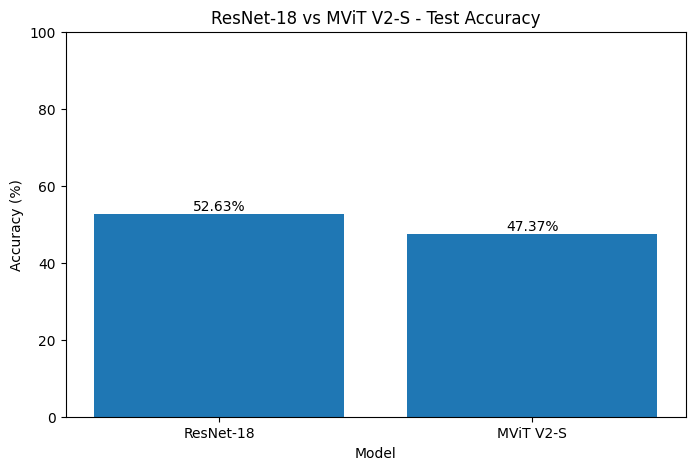

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Test Accuracy (%)"]
)

plt.title("ResNet-18 vs MViT V2-S - Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(results["Test Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

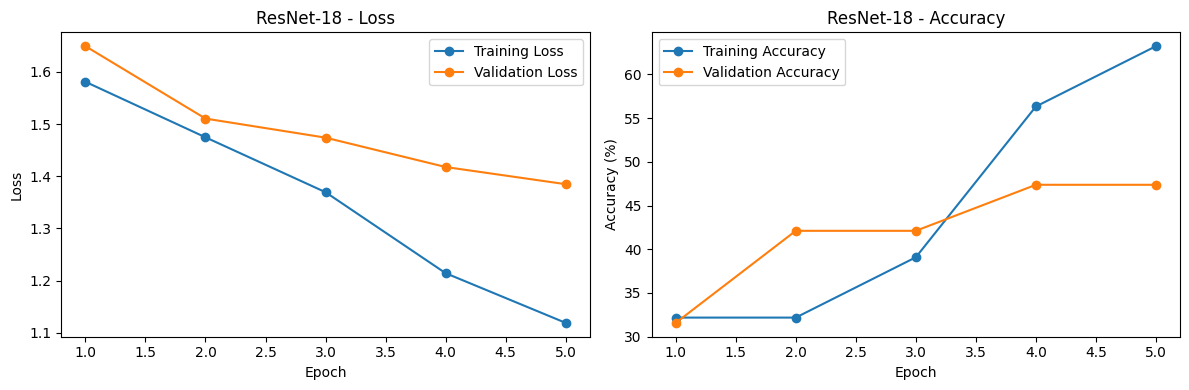

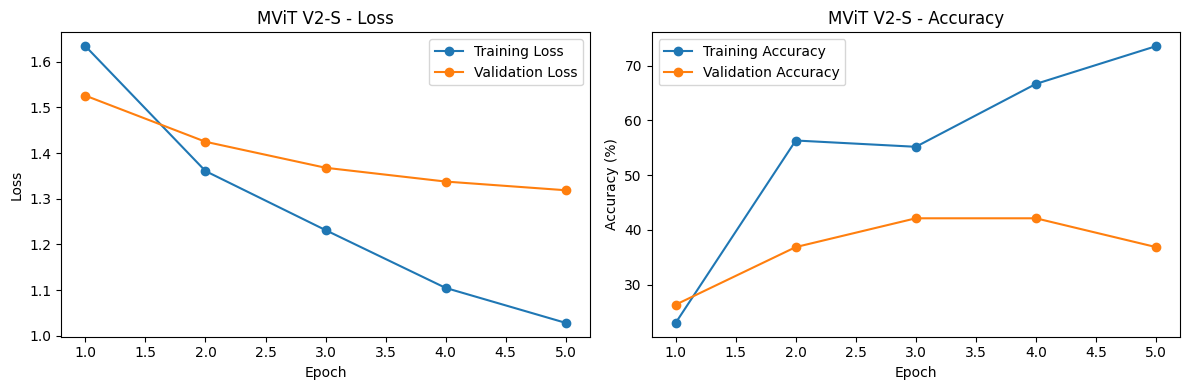

In [20]:
def plot_history(history, model_name):

    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
    plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    plt.title(model_name + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
    plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
    plt.title(model_name + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()

    plt.tight_layout()
    plt.show()


plot_history(resnet_history, "ResNet-18")
plot_history(mvit_history, "MViT V2-S")

In [21]:
print("RESNET-18 CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    resnet_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))


print("\nMViT V2-S CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    mvit_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

RESNET-18 CLASSIFICATION REPORT

              precision    recall  f1-score   support

    graphite       1.00      0.25      0.40         4
         ink       0.44      1.00      0.62         4
         oil       0.50      0.50      0.50         4
      pastel       0.67      0.50      0.57         4
 watercolour       0.50      0.33      0.40         3

    accuracy                           0.53        19
   macro avg       0.62      0.52      0.50        19
weighted avg       0.63      0.53      0.50        19


MViT V2-S CLASSIFICATION REPORT

              precision    recall  f1-score   support

    graphite       0.40      0.50      0.44         4
         ink       0.40      0.50      0.44         4
         oil       0.50      0.50      0.50         4
      pastel       0.75      0.75      0.75         4
 watercolour       0.00      0.00      0.00         3

    accuracy                           0.47        19
   macro avg       0.41      0.45      0.43        19
weighted a

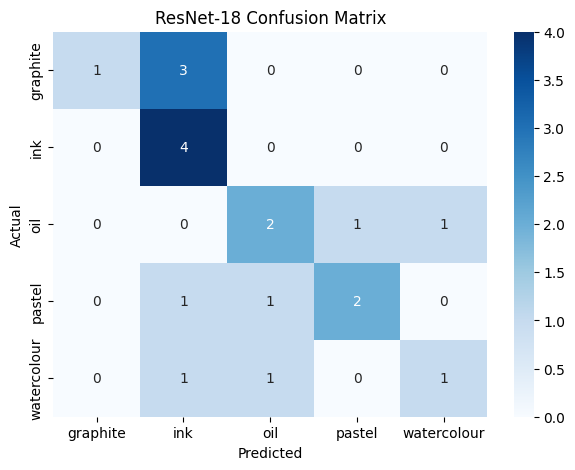

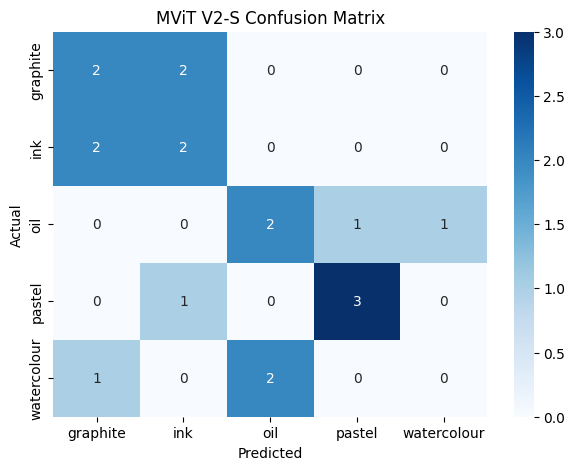

In [22]:
resnet_cm = confusion_matrix(
    y_true,
    resnet_pred,
    labels=np.arange(len(class_names))
)

mvit_cm = confusion_matrix(
    y_true,
    mvit_pred,
    labels=np.arange(len(class_names))
)


plt.figure(figsize=(7, 5))
sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("ResNet-18 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


plt.figure(figsize=(7, 5))
sns.heatmap(
    mvit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("MViT V2-S Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

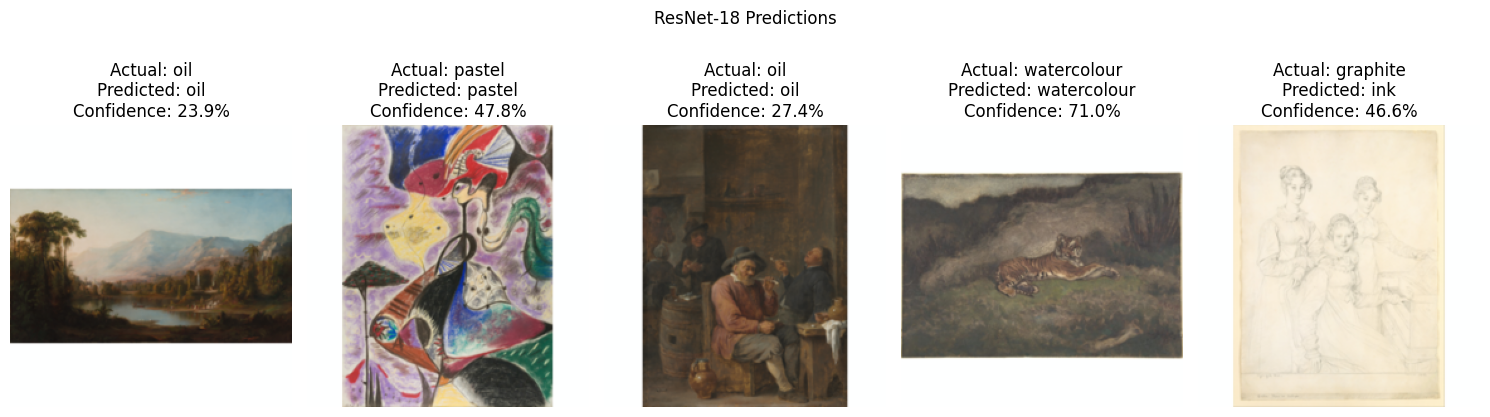

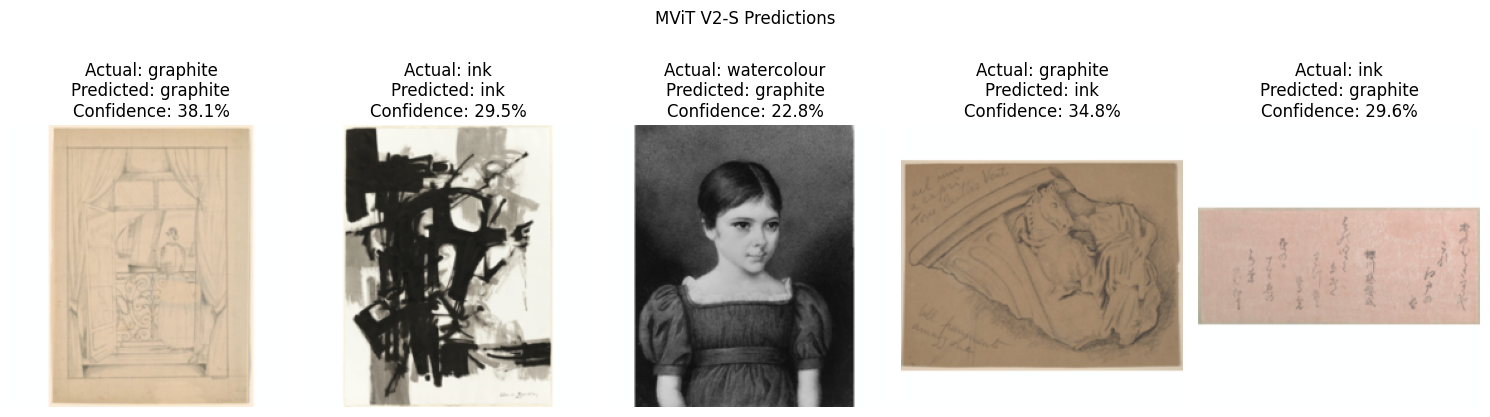

In [23]:
def show_predictions(model, dataset, model_name, number_of_images=5):

    model.eval()

    indices = np.random.choice(
        len(dataset),
        size=min(number_of_images, len(dataset)),
        replace=False
    )

    plt.figure(figsize=(15, 5))

    for plot_index, dataset_index in enumerate(indices):

        image, actual_label = dataset[dataset_index]

        with torch.no_grad():

            output = model(image.unsqueeze(0).to(device))

            probabilities = torch.softmax(output, dim=1)[0]

            predicted_label = probabilities.argmax().item()

        # Convert normalized tensor back for display
        display_image = image.permute(1, 2, 0).cpu().numpy()
        display_image = display_image * np.array([0.229, 0.224, 0.225])
        display_image = display_image + np.array([0.485, 0.456, 0.406])
        display_image = np.clip(display_image, 0, 1)

        plt.subplot(1, len(indices), plot_index + 1)
        plt.imshow(display_image)
        plt.axis("off")

        plt.title(
            f"Actual: {class_names[actual_label]}\n"
            f"Predicted: {class_names[predicted_label]}\n"
            f"Confidence: {probabilities[predicted_label].item()*100:.1f}%"
        )

    plt.suptitle(model_name + " Predictions")
    plt.tight_layout()
    plt.show()


show_predictions(
    resnet_model,
    test_dataset,
    "ResNet-18"
)

show_predictions(
    mvit_model,
    test_dataset,
    "MViT V2-S"
)

# Trained model saving & download

In [24]:
import os
import torch

RESULTS_DIR = "/content/phase2_results"

os.makedirs(RESULTS_DIR, exist_ok=True)


# Save ResNet-18
torch.save({
    "model_state_dict": resnet_model.state_dict(),
    "class_names": class_names
}, f"{RESULTS_DIR}/resnet18_best.pth")


# Save MViT V2-S
torch.save({
    "model_state_dict": mvit_model.state_dict(),
    "class_names": class_names
}, f"{RESULTS_DIR}/mvit_v2_s_best.pth")


print("Both trained models saved successfully!")

Both trained models saved successfully!


In [25]:
results.to_csv(
    f"{RESULTS_DIR}/model_comparison.csv",
    index=False
)

print("Model comparison CSV saved!")

Model comparison CSV saved!


In [26]:
history_df = pd.DataFrame({
    "epoch": range(1, NUM_EPOCHS + 1),

    "resnet_train_loss": resnet_history["train_loss"],
    "resnet_val_loss": resnet_history["val_loss"],
    "resnet_train_accuracy": resnet_history["train_accuracy"],
    "resnet_val_accuracy": resnet_history["val_accuracy"],

    "mvit_train_loss": mvit_history["train_loss"],
    "mvit_val_loss": mvit_history["val_loss"],
    "mvit_train_accuracy": mvit_history["train_accuracy"],
    "mvit_val_accuracy": mvit_history["val_accuracy"]
})

history_df.to_csv(
    f"{RESULTS_DIR}/training_history.csv",
    index=False
)

print("Training history CSV saved!")

Training history CSV saved!


In [27]:
with open(f"{RESULTS_DIR}/classification_reports.txt", "w") as file:

    file.write("RESNET-18 CLASSIFICATION REPORT\n\n")

    file.write(classification_report(
        y_true,
        resnet_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    file.write("\n\nMViT V2-S CLASSIFICATION REPORT\n\n")

    file.write(classification_report(
        y_true,
        mvit_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

print("Classification reports saved!")

Classification reports saved!


In [28]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet-18 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig(f"{RESULTS_DIR}/resnet_confusion_matrix.png", bbox_inches="tight")
plt.close()


plt.figure(figsize=(7, 5))

sns.heatmap(
    mvit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MViT V2-S Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig(f"{RESULTS_DIR}/mvit_confusion_matrix.png", bbox_inches="tight")
plt.close()


print("Confusion matrices saved!")

Confusion matrices saved!


In [29]:
# Accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["Test Accuracy (%)"])
plt.title("ResNet-18 vs MViT V2-S - Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(results["Test Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.savefig(
    f"{RESULTS_DIR}/model_accuracy_comparison.png",
    bbox_inches="tight"
)

plt.close()


# Training curves
for history, name in [
    (resnet_history, "resnet18"),
    (mvit_history, "mvit_v2_s")
]:

    epochs = range(1, NUM_EPOCHS + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
    plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(name + " Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
    plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(name + " Accuracy")
    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"{RESULTS_DIR}/{name}_training_curves.png",
        bbox_inches="tight"
    )

    plt.close()


print("Graphs saved!")

Graphs saved!


In [30]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/phase2_results",
    "zip",
    RESULTS_DIR
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Note: We used different batch sizes because the computational requirements of ResNet-18 and MViT V2-S differ. MViT V2-S requires more GPU memory in our image-to-video adaptation, so we reduced its batch size to avoid out-of-memory errors. Both models use the same dataset, train-validation-test split, preprocessing, and test samples. Therefore, their final test accuracies are evaluated on the same data.

MViT is more computationally complex and is particularly designed to exploit spatiotemporal information. Our dataset contains still images, so we adapted them for MViT by repeating frames, which does not introduce new temporal information. Also, our dataset has only 125 images, with only 87 training images. Therefore, the more complex MViT architecture may not have had enough suitable data to demonstrate its advantage. Additionally, the difference is only one correctly classified test image out of 19.

# Loading Saved Models for Demo (our custom dataset)

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
checkpoint = torch.load(
    "resnet18_best.pth",
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]

resnet_model = create_resnet(len(class_names))

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("ResNet-18 loaded successfully!")

In [ ]:
checkpoint = torch.load(
    "mvit_v2_s_best.pth",
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]

mvit_model = create_mvit(len(class_names))

mvit_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mvit_model = mvit_model.to(device)
mvit_model.eval()

print("MViT V2-S loaded successfully!")

In [ ]:
from google.colab import files

files.download("/content/phase2_results/model_comparison.csv")
files.download("/content/phase2_results/training_history.csv")